# Entendimiento de los Datos

## Índice

- [Librerías y lectura del archivo](#librerías-y-lectura-del-archivo)
- [Segmentación de datasets (System y LLM)](#segmentación-de-datasets-system--llm)
  - [System](#system)
    - [Descripción general de los datos](#descripción-general-de-los-datos)
    - [Tipos de variables](#tipos-de-variables)
    - [Valores nulos](#valores-nulos)
    - [Variables categóricas](#variables-categóricas)
    - [Conclusión análisis System](#conclusión-análisis-system)
  - [LLM](#llm)
    - [Descripción general de los datos](#descripción-general-de-los-datos-1)
    - [Tipos de variables](#tipos-de-variables-1)
    - [Valores nulos](#valores-nulos-1)
    - [Variables numéricas](#variables-numéricas)
    - [Variables categóricas](#variables-categóricas-1)
    - [Conclusión análisis LLM](#conclusión-análisis-llm)

## Librerías y Lectura del archivo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/logs.csv')
df.head()

,_id,_ignored,_index,_score,@timestamp,@version,event_code_version,event_hash,@event_time_requested,headers_content_type,...,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_status,llm_error_message,llm_cost_usd,llm_temperature,llm_top_p,llm_stream,llm_finish_reason
0,23bb795f-593c-4f5b-95f6-9ed2ee49d447,NaN,sap-logs-2026.04,0.7863,2026-04-17T22:12:18.000Z,1,1.8.7,bb746db61f0d38437ff6e0e4a3a425399f925aa0333352...,2026-04-17T22:12:17.748Z,application/json,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,a112d657-a776-4029-99fa-a9660dbae0de,NaN,sap-logs-2026.04,0.7308,2026-04-11T17:03:42.000Z,1,3.3.1,bcfb7885820cd48670812afd73f1537747eebf3ba54272...,2026-04-11T17:03:41.551Z,text/plain,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,e6c68fea-c4c2-4dd5-9335-f503f43731a9,NaN,sap-logs-2026.04,0.6168,2026-04-11T06:28:17.000Z,1,1.6.2,8f681cbb899fa6ef1832c56566c0ccfc0fe43bb936b2d9...,2026-04-11T06:28:16.705Z,application/x-www-form-urlencoded,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,75225251-b3d5-4a76-97dc-9fcc5f29eeba,NaN,llm-logs-2026.04,0.9530,2026-04-12T12:57:39.000Z,1,1.8.9,ad44a6f8dc6cbad0036218cbc65ae386ab53c846bfe686...,2026-04-12T12:57:38.340Z,application/xml,...,2680.0,31911.58,NaN,timeout,Request timed out after 30 s.,0.0536,0.26,0.92,False,timeout
4,4ad51ca3-c950-4bfb-9914-d4d9e1f104c6,NaN,sap-logs-2026.04,0.5392,2026-04-12T06:35:20.000Z,1,3.4.0,ccb84bedaa608eaf29f7b5347708d19fa39bfd29504b11...,2026-04-12T06:35:19.946Z,application/xml,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Segmentación de Datasets (System & LLM)

In [4]:
df_llm = df[df['_index'].str.startswith('llm-logs', na=False)]
df_llm = df_llm.drop(columns=['_ignored', 'http_status_code', 'service_id', 'client_ip'])
df_system = df[df['_index'].str.startswith('sap-logs', na=False)]
df_system = df_system.drop(columns=['llm_error_message', 'llm_response_size_bytes', 'sap_llm_response_size', 'sap_llm_response_time', 'llm_prompt_tokens', 'llm_completion_tokens', 'llm_total_tokens', 'llm_response_time_ms', 'llm_model_id', 'llm_status', 'llm_cost_usd', 'llm_prompt_category', 'llm_temperature', 'llm_top_p', 'llm_stream', 'llm_finish_reason', 'llm_prompt_id', 'llm_provider', 'llm_prompt'])

## System

### Descripción general de los datos

In [5]:
print("Primeros 5 datos del dataframe de logs System:")
display(df_system.head())

print("Descripción estadística del dataframe de logs System:")
display(df_system.describe())

print("Información del dataframe de logs System:")
display(df_system.info())

Primeros 5 datos del dataframe de logs System:


,_id,_ignored,_index,_score,@timestamp,@version,event_code_version,event_hash,@event_time_requested,headers_content_type,...,sap_function_log_type,sap_function_message,sap_app_env,region_id,region_name,region_code,macro_region,service_id,http_status_code,client_ip
0,23bb795f-593c-4f5b-95f6-9ed2ee49d447,NaN,sap-logs-2026.04,0.7863,2026-04-17T22:12:18.000Z,1,1.8.7,bb746db61f0d38437ff6e0e4a3a425399f925aa0333352...,2026-04-17T22:12:17.748Z,application/json,...,INFO,Semantic cache hit — previous LLM response reu...,development,AU-003,Australia | Sydney (2),AU-SYD2,Australia,analytics-engine,200.0,208.223.2.195
1,a112d657-a776-4029-99fa-a9660dbae0de,NaN,sap-logs-2026.04,0.7308,2026-04-11T17:03:42.000Z,1,3.3.1,bcfb7885820cd48670812afd73f1537747eebf3ba54272...,2026-04-11T17:03:41.551Z,text/plain,...,INFO,Cron expression validated and scheduled for sa...,qa,AS-016,Singapore,SG,Asia,analytics-engine,200.0,7.144.51.184
2,e6c68fea-c4c2-4dd5-9335-f503f43731a9,NaN,sap-logs-2026.04,0.6168,2026-04-11T06:28:17.000Z,1,1.6.2,8f681cbb899fa6ef1832c56566c0ccfc0fe43bb936b2d9...,2026-04-11T06:28:16.705Z,application/x-www-form-urlencoded,...,INFO,Idle connection reclaimed from pool for sap-co...,qa,AS-005,China | Shanghai,CN-SHA,Asia,analytics-engine,301.0,192.168.7.55
4,4ad51ca3-c950-4bfb-9914-d4d9e1f104c6,NaN,sap-logs-2026.04,0.5392,2026-04-12T06:35:20.000Z,1,3.4.0,ccb84bedaa608eaf29f7b5347708d19fa39bfd29504b11...,2026-04-12T06:35:19.946Z,application/xml,...,INFO,Notification dispatched from sap-fiori-launchp...,qa,NA-009,"USA | Ashburn, VA",US-ASH,North America,notification-service,200.0,192.168.6.187
6,256d1a64-e1ed-4b13-b9b1-d239ee992c2e,NaN,sap-logs-2026.04,0.9945,2026-04-17T19:57:04.000Z,1,3.5.2,eb4653ece64ecf9f32fd9463f4521782db0f0b06f64959...,2026-04-17T19:57:03.805Z,application/xml,...,INFO,SAP Joule skill invocation completed without e...,production,EU-030,Switzerland | Zurich,CH-ZRH,Europe,cache-service,301.0,103.93.57.36


Descripción estadística del dataframe de logs System:


,_ignored,_score,@version,http_status_code
count,0.0,1.158847e+06,1158847.0,1.158847e+06
mean,NaN,7.498346e-01,1.0,2.627992e+02
std,NaN,1.444649e-01,0.0,1.025674e+02
min,NaN,5.000000e-01,1.0,2.000000e+02
25%,NaN,6.247000e-01,1.0,2.000000e+02
50%,NaN,7.498000e-01,1.0,2.000000e+02
75%,NaN,8.750000e-01,1.0,3.020000e+02
max,NaN,1.000000e+00,1.0,5.040000e+02


Información del dataframe de logs System:
<class 'pandas.DataFrame'>
Index: 1158847 entries, 0 to 1931411
Data columns (total 25 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   _id                          1158847 non-null  str    
 1   _ignored                     0 non-null        float64
 2   _index                       1158847 non-null  str    
 3   _score                       1158847 non-null  float64
 4   @timestamp                   1158847 non-null  str    
 5   @version                     1158847 non-null  int64  
 6   event_code_version           1158847 non-null  str    
 7   event_hash                   1158847 non-null  str    
 8   @event_time_requested        1158847 non-null  str    
 9   headers_content_type         1158847 non-null  str    
 10  headers_http_host            1158847 non-null  str    
 11  headers_http_request_method  1158847 non-null  str    
 12  heathers_request

None

### Tipos de variables

In [6]:
# Clasificación semántica de las variables de df_system
clasificacion_variables = {
    'Numéricas continuas': ['_score'],
    # @version es un valor entero de metadatos (constante en este dataset).
    'Numéricas discretas': ['@version'],
    'Categóricas': [
        '_index', 'event_code_version', 'headers_content_type',
        'headers_http_host', 'headers_http_request_method',
        'heathers_request_path', 'sap_function_application',
        'sap_source_type', 'sap_function_log_type', 'sap_app_env',
        'region_id', 'region_name', 'region_code', 'macro_region',
        # Es un código de estado, no una magnitud numérica.
        'http_status_code'
    ],
    # No hay columnas ordinales identificadas en df_system.
    'Ordinales': [],
    'Fechas o temporales': ['@timestamp', '@event_time_requested']
}

# Se reportan aparte porque no representan mediciones ni categorías analíticas.
columnas_no_analiticas = {
    'Identificadores': ['_id', 'event_hash', 'service_id', 'client_ip'],
    'Texto libre': ['sap_function_message'],
    'Sin información': ['_ignored']
}

grupos = {**clasificacion_variables, **columnas_no_analiticas}
columnas_asignadas = [columna for columnas in grupos.values() for columna in columnas]
duplicadas = sorted({columna for columna in columnas_asignadas if columnas_asignadas.count(columna) > 1})
inexistentes = sorted(set(columnas_asignadas) - set(df_system.columns))
sin_clasificar = sorted(set(df_system.columns) - set(columnas_asignadas))

if duplicadas or inexistentes or sin_clasificar:
    raise ValueError(
        'Revisa la clasificación de df_system. '
        f'Duplicadas: {duplicadas}; columnas inexistentes: {inexistentes}; '
        f'sin clasificar: {sin_clasificar}'
    )

print('=== CLASIFICACIÓN DE VARIABLES: df_system ===\n')
for tipo, columnas in clasificacion_variables.items():
    print(f'{tipo} ({len(columnas)}): {columnas if columnas else "Ninguna"}')

print('\nColumnas no analíticas (se reportan aparte):')
for tipo, columnas in columnas_no_analiticas.items():
    print(f'{tipo} ({len(columnas)}): {columnas}')

print(f'\nValidación: las {len(columnas_asignadas)} columnas de df_system están asignadas una sola vez.')

=== CLASIFICACIÓN DE VARIABLES: df_system ===

Numéricas continuas (1): ['_score']
Numéricas discretas (1): ['@version']
Categóricas (15): ['_index', 'event_code_version', 'headers_content_type', 'headers_http_host', 'headers_http_request_method', 'heathers_request_path', 'sap_function_application', 'sap_source_type', 'sap_function_log_type', 'sap_app_env', 'region_id', 'region_name', 'region_code', 'macro_region', 'http_status_code']
Ordinales (0): Ninguna
Fechas o temporales (2): ['@timestamp', '@event_time_requested']

Columnas no analíticas (se reportan aparte):
Identificadores (4): ['_id', 'event_hash', 'service_id', 'client_ip']
Texto libre (1): ['sap_function_message']
Sin información (1): ['_ignored']

Validación: las 25 columnas de df_system están asignadas una sola vez.


### Valores nulos

In [7]:
null_info_system = pd.DataFrame({
    'Valores Nulos': df_system.isnull().sum(),
    'Porcentaje (%)': (df_system.isnull().sum() / len(df_system)) * 100
}).sort_values(by='Valores Nulos', ascending=False)

# Filtrar para mostrar solo las columnas que contienen nulos
null_info_filtered_system = null_info_system[null_info_system['Valores Nulos'] > 0]
print("=== COLUMNAS CON VALORES NULOS ===")
display(null_info_filtered_system)

=== COLUMNAS CON VALORES NULOS ===


,Valores Nulos,Porcentaje (%)
_ignored,1158847,100.0


### Variables categóricas

De momento solo estamos checando las que tengan una cardinalidad menor a 20 ya que cardinalidades superiores requieren una transformación de los datos si se detecta que son relevantes para el modelo.

In [20]:
def revisar_categoricas(df, clasificacion_variables, limite=30):
    columnas = clasificacion_variables.get('Categóricas', [])

    for columna in columnas:
        cantidad = df[columna].nunique()

        if cantidad < limite:
            print(f"{columna}: {cantidad} valores únicos")
            print(f"  Valores: {df[columna].unique().tolist()}")

In [21]:
revisar_categoricas(df_system, clasificacion_variables)

_index: 1 valores únicos
  Valores: ['sap-logs-2026.04']
headers_content_type: 5 valores únicos
  Valores: ['application/json', 'text/plain', 'application/x-www-form-urlencoded', 'application/xml', 'multipart/form-data']
headers_http_request_method: 5 valores únicos
  Valores: ['GET', 'DELETE', 'POST', 'PATCH', 'PUT']
sap_function_application: 10 valores únicos
  Valores: ['sap-fiori-launchpad', 'sap-data-sphere', 'sap-concur', 'sap-analytics-cloud', 'sap-btp-cf', 'sap-successfactors', 'sap-s4hana-sales', 'sap-s4hana-finance', 'sap-intelligent-rpa', 'sap-ariba']
sap_source_type: 7 valores únicos
  Valores: ['REST', 'RFC', 'OData', 'BAPI', 'BTP-Event', 'SOAP', 'IDOC']
sap_function_log_type: 7 valores únicos
  Valores: ['INFO', 'PERF', 'WARNING', 'AUDIT', 'DEBUG', 'ERROR', 'SECURITY']
sap_app_env: 5 valores únicos
  Valores: ['development', 'qa', 'production', 'sandbox', 'staging']
macro_region: 6 valores únicos
  Valores: ['Australia', 'Asia', 'North America', 'Europe', 'Middle East & A

In [22]:
def graficar_categoricas(df, clasificacion_variables):
    columnas = [columna for columna in clasificacion_variables.get('Categóricas', []) if df[columna].nunique() < 30]

    for columna in columnas:
        conteos = df[columna].value_counts(dropna=False)

        ax = conteos.plot(kind='bar', figsize=(10, 5), color='steelblue')
        ax.set_title(f'Frecuencia de valores: {columna}')
        ax.set_xlabel('Valor')
        ax.set_ylabel('Número de apariciones')
        ax.tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

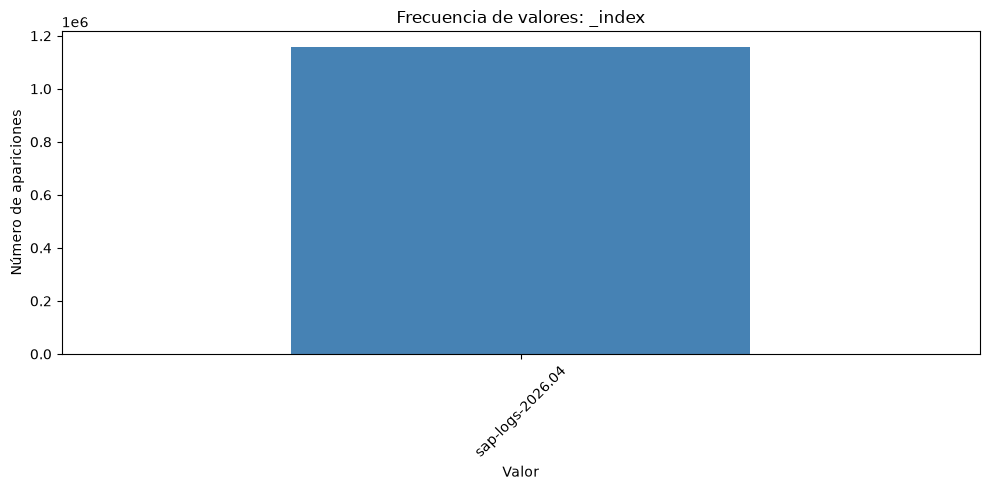

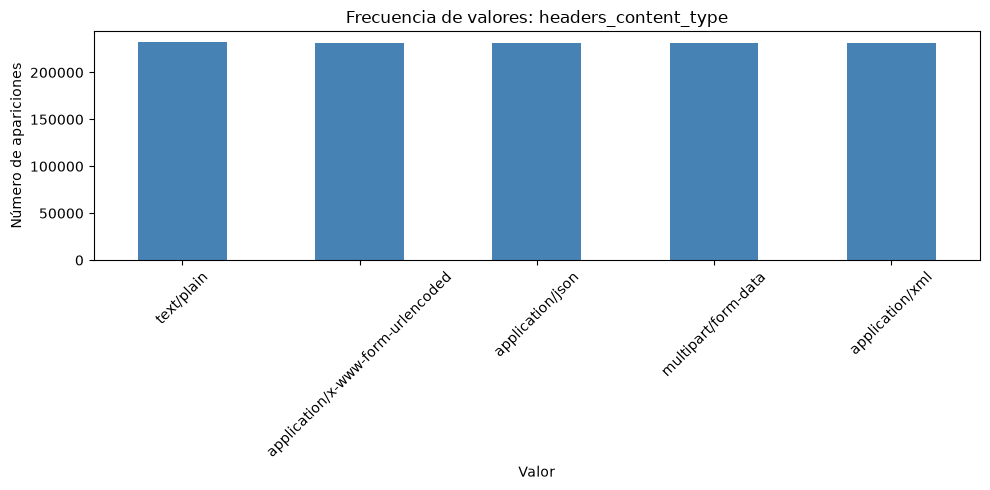

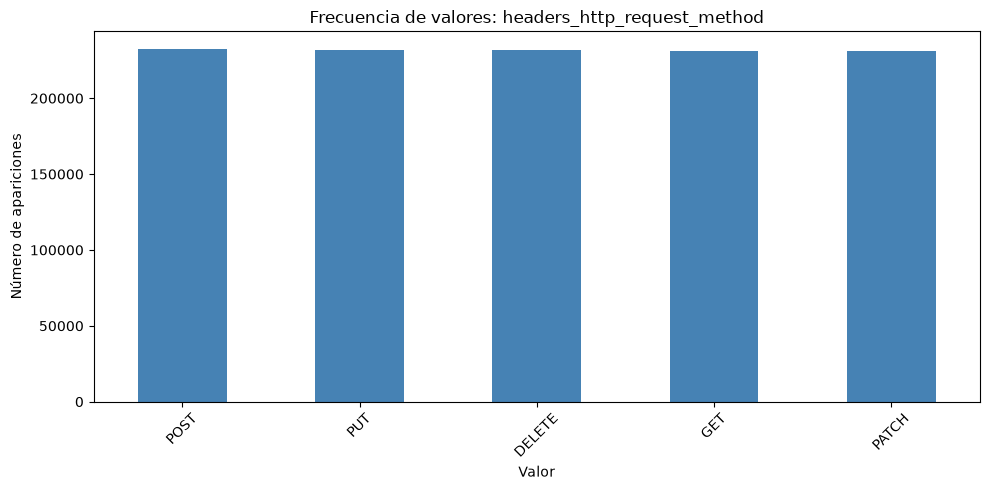

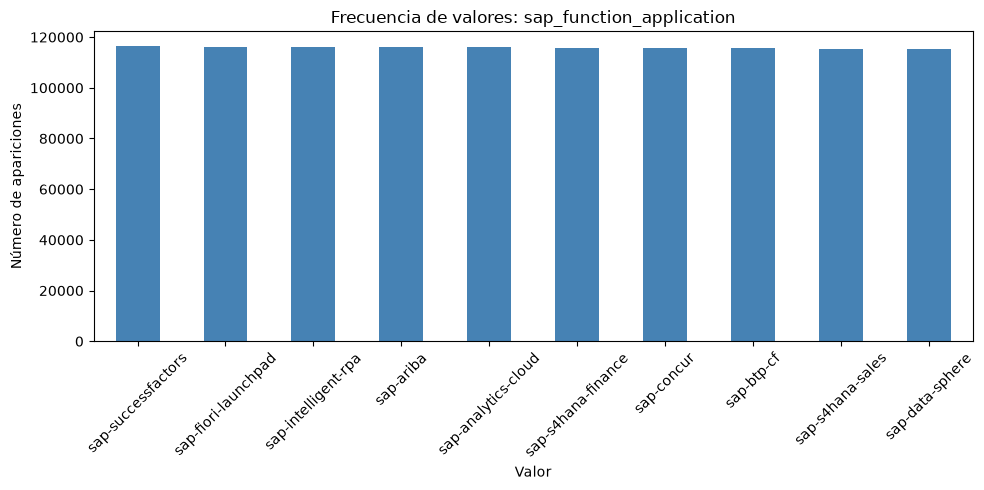

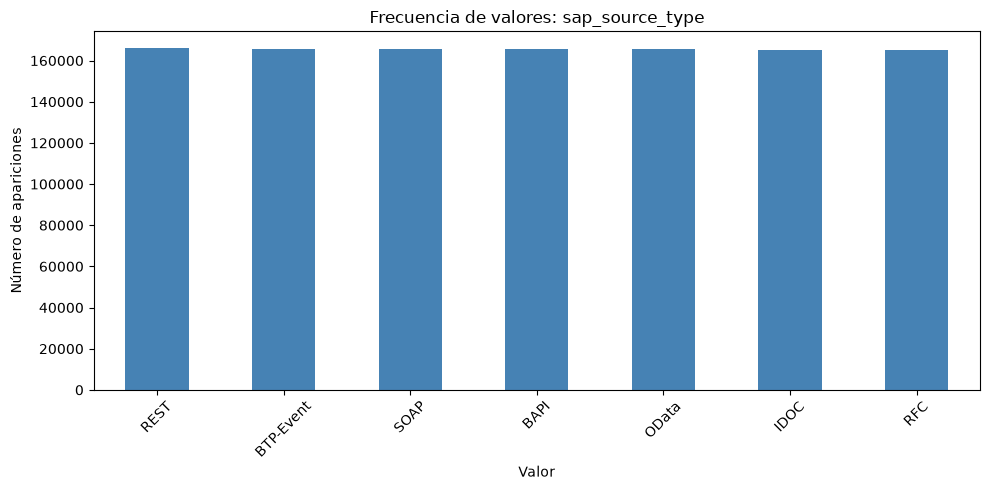

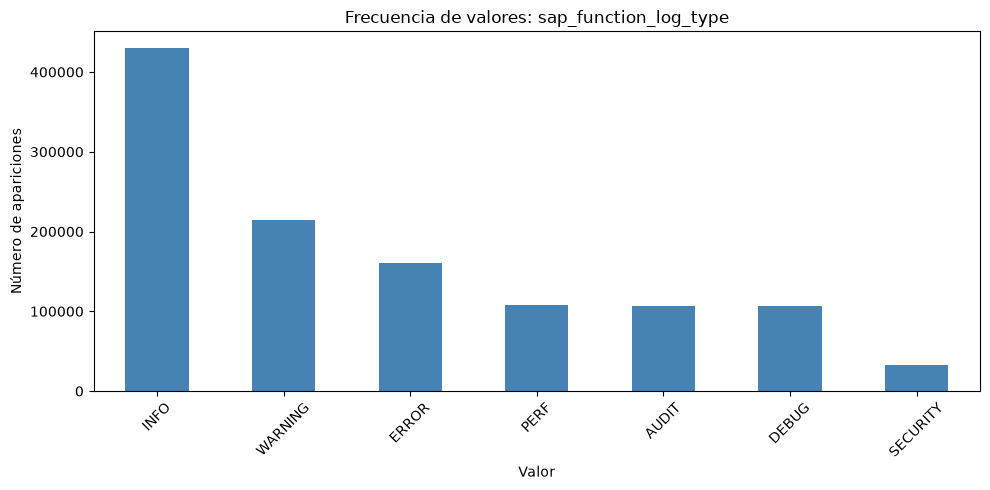

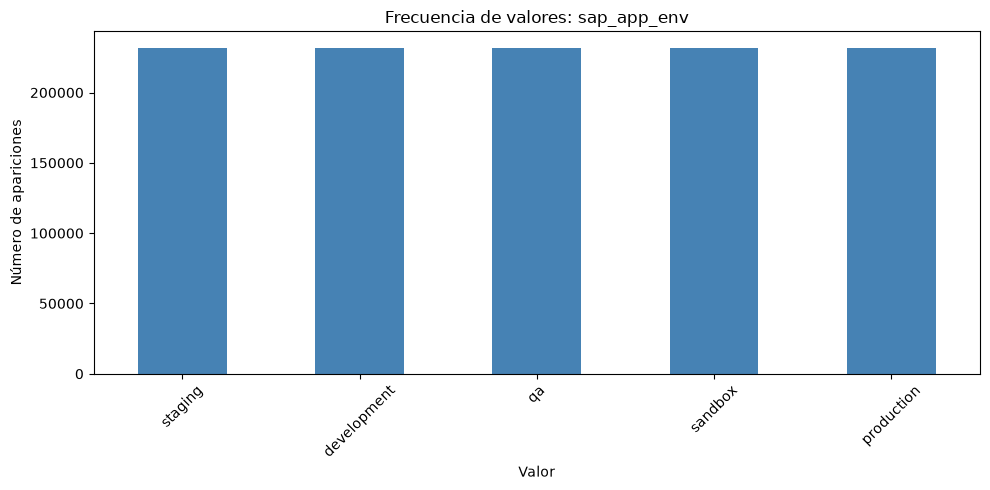

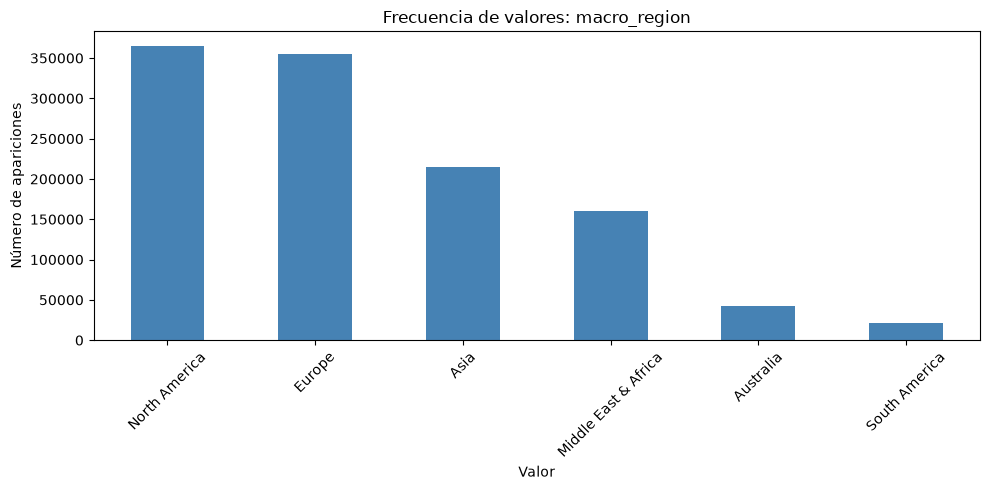

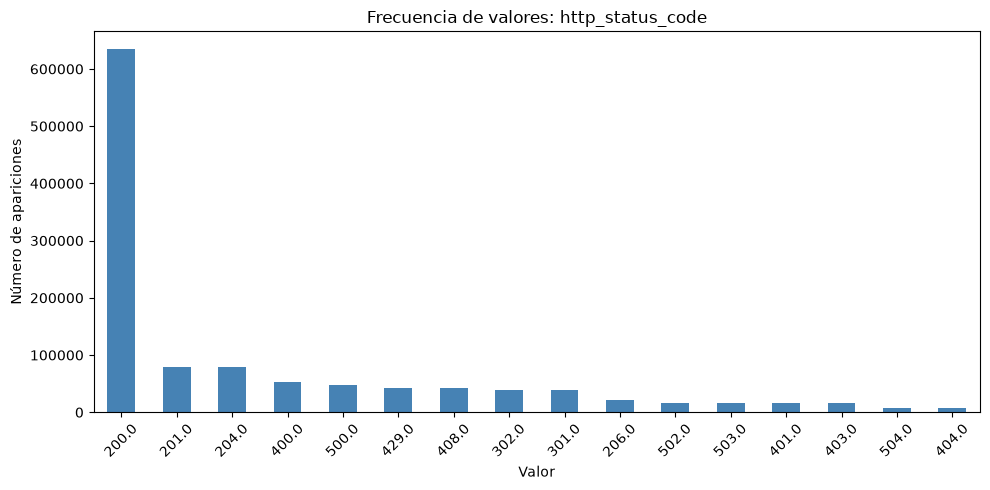

In [ ]:
graficar_categoricas(df_system, clasificacion_variables)

### Conclusión análisis System

La mayoría de datos se encuentran extremadamente balanceados por lo que identificar outliers en eventos aislados es una tarea muy complicada. Las columnas clave identificadas en este dataset son "http_status_code", "sap_function_log_type", "headers_http_request_method" y "sap_app_env".

Se eliminará la columna "_ignored" ya que cuenta con 100% de valores nulos y no aporta al análisis.

El siguiente paso será producir las ventanas de 5 minutos para realizar un análisis mucho más preciso con el conteo agrupado de eventos dentro de esas ventanas y descubrir si el "balance" de los datos se debe precisamente a ventanas donde alguna anomalía "infló" alguna métrica.

## LLM

### Descripción general de los datos

In [9]:
print("Primeros 5 datos del dataframe de logs LLM:")
display(df_llm.head())

print("Descripción estadística del dataframe de logs LLM:")
display(df_llm.describe())

print("Información del dataframe de logs LLM:")
display(df_llm.info())

Primeros 5 datos del dataframe de logs LLM:


,_id,_index,_score,@timestamp,@version,event_code_version,event_hash,@event_time_requested,headers_content_type,headers_http_host,...,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_status,llm_error_message,llm_cost_usd,llm_temperature,llm_top_p,llm_stream,llm_finish_reason
3,75225251-b3d5-4a76-97dc-9fcc5f29eeba,llm-logs-2026.04,0.9530,2026-04-12T12:57:39.000Z,1,1.8.9,ad44a6f8dc6cbad0036218cbc65ae386ab53c846bfe686...,2026-04-12T12:57:38.340Z,application/xml,llm.nl-eem.sap-ai.internal,...,2680.0,31911.58,NaN,timeout,Request timed out after 30 s.,0.053600,0.26,0.92,False,timeout
5,ce447f59-bc79-4c68-a542-30fafada60c3,llm-logs-2026.04,0.8932,2026-04-15T18:14:01.000Z,1,3.8.1,4a1649c674e7b9b688f0a0e9ebbe7db8cf06794238b482...,2026-04-15T18:14:00.231Z,multipart/form-data,llm.za-cpt.sap-ai.internal,...,869.0,3701.06,30770.0,success,NaN,0.017380,1.12,0.64,False,stop
9,354208c1-03fc-4364-b222-3d10e7049965,llm-logs-2026.04,0.7756,2026-04-12T20:31:36.000Z,1,1.6.5,b426a6f87e7616213fcd65d08b93da93c52c78c254fede...,2026-04-12T20:31:35.385Z,multipart/form-data,llm.us-oh.sap-ai.internal,...,2155.0,11893.71,29280.0,success,NaN,0.010775,0.06,0.77,False,length
10,aa6c3b38-eaef-4970-a4dc-f480bafd864b,llm-logs-2026.04,0.5205,2026-04-12T02:08:14.000Z,1,2.9.6,fdff50d9f4e36975c8dfd2ed75167bc14d80079ef80c63...,2026-04-12T02:08:13.287Z,application/x-www-form-urlencoded,llm.us-az.sap-ai.internal,...,2418.0,3173.22,21278.0,success,NaN,0.000605,0.46,0.73,False,stop
14,76c9496e-e38e-4e0e-8ad2-0c2b6d566189,llm-logs-2026.04,0.9344,2026-04-15T01:53:26.000Z,1,1.2.2,5d0a44ff87125b826d412bea0189b23ad130040ebfacbd...,2026-04-15T01:53:25.515Z,application/x-www-form-urlencoded,llm.us-tx.sap-ai.internal,...,3270.0,2956.56,7941.0,success,NaN,0.016350,0.73,0.72,True,stop


Descripción estadística del dataframe de logs LLM:


,_score,@version,sap_llm_response_size,sap_llm_response_time,llm_prompt_tokens,llm_completion_tokens,llm_total_tokens,llm_response_time_ms,llm_response_size_bytes,llm_cost_usd,llm_temperature,llm_top_p
count,772565.000000,772565.0,540459.000000,772565.000000,772565.000000,772565.000000,772565.000000,772565.000000,540459.000000,772565.000000,772565.000000,772565.000000
mean,0.750167,1.0,16503.841842,8772.606362,1023.053338,764.707612,1787.760950,8772.606362,16503.841842,0.012463,0.749752,0.749939
std,0.144423,0.0,9395.425989,8726.652008,563.181345,424.944257,705.779483,8726.652008,9395.425989,0.018865,0.432674,0.144389
min,0.500000,1.0,256.000000,200.000000,50.000000,30.000000,82.000000,200.000000,256.000000,0.000007,0.000000,0.500000
25%,0.625200,1.0,8354.000000,2296.770000,535.000000,396.000000,1274.000000,2296.770000,8354.000000,0.000752,0.380000,0.620000
50%,0.750300,1.0,16478.000000,6517.320000,1023.000000,764.000000,1788.000000,6517.320000,16478.000000,0.005424,0.750000,0.750000
75%,0.875200,1.0,24656.000000,11816.970000,1510.000000,1133.000000,2301.000000,11816.970000,24656.000000,0.014664,1.120000,0.870000
max,1.000000,1.0,32768.000000,34999.990000,2000.000000,1500.000000,3496.000000,34999.990000,32768.000000,0.139720,1.500000,1.000000


Información del dataframe de logs LLM:
<class 'pandas.DataFrame'>
Index: 772565 entries, 3 to 1931410
Data columns (total 40 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   _id                          772565 non-null  str    
 1   _index                       772565 non-null  str    
 2   _score                       772565 non-null  float64
 3   @timestamp                   772565 non-null  str    
 4   @version                     772565 non-null  int64  
 5   event_code_version           772565 non-null  str    
 6   event_hash                   772565 non-null  str    
 7   @event_time_requested        772565 non-null  str    
 8   headers_content_type         772565 non-null  str    
 9   headers_http_host            772565 non-null  str    
 10  headers_http_request_method  772565 non-null  str    
 11  heathers_request_path        772565 non-null  str    
 12  sap_function_application     77256

None

### Tipos de variables

In [10]:
# Clasificación semántica de las variables de df_llm
clasificacion_variables_llm = {
    'Numéricas continuas': [
        'sap_llm_response_time', 'llm_response_time_ms', 'llm_cost_usd',
        'llm_temperature', 'llm_top_p'
    ],
    'Numéricas discretas': [
        '@version', 'sap_llm_response_size', 'llm_prompt_tokens',
        'llm_completion_tokens', 'llm_total_tokens',
        'llm_response_size_bytes'
    ],
    'Categóricas': [
        '_index', 'event_code_version', 'headers_content_type',
        'headers_http_host', 'headers_http_request_method',
        'heathers_request_path', 'sap_function_application',
        'sap_source_type', 'sap_function_log_type', 'sap_app_env',
        'region_id', 'region_name', 'region_code', 'macro_region',
        'llm_model_id', 'llm_provider', 'llm_prompt_category',
        'llm_status', 'llm_stream', 'llm_finish_reason'
    ],
    'Ordinales': [],
    'Fechas o temporales': ['@timestamp', '@event_time_requested']
}

# Se reportan aparte porque no son variables analíticas de las cinco clases.
columnas_no_analiticas_llm = {
    'Metadatos': ['_score'],
    'Identificadores': ['_id', 'event_hash', 'llm_prompt_id'],
    'Texto libre': ['sap_function_message', 'llm_prompt', 'llm_error_message']
}

grupos_llm = {**clasificacion_variables_llm, **columnas_no_analiticas_llm}
columnas_asignadas_llm = [
    columna for columnas in grupos_llm.values() for columna in columnas
]
duplicadas_llm = sorted({
    columna for columna in columnas_asignadas_llm
    if columnas_asignadas_llm.count(columna) > 1
})
inexistentes_llm = sorted(set(columnas_asignadas_llm) - set(df_llm.columns))
sin_clasificar_llm = sorted(set(df_llm.columns) - set(columnas_asignadas_llm))

if duplicadas_llm or inexistentes_llm or sin_clasificar_llm:
    raise ValueError(
        'Revisa la clasificación de df_llm. '
        f'Duplicadas: {duplicadas_llm}; columnas inexistentes: {inexistentes_llm}; '
        f'sin clasificar: {sin_clasificar_llm}'
    )

print('=== CLASIFICACIÓN DE VARIABLES: df_llm ===\n')
for tipo, columnas in clasificacion_variables_llm.items():
    print(f'{tipo} ({len(columnas)}): {columnas if columnas else "Ninguna"}')

print('\nColumnas no analíticas (se reportan aparte):')
for tipo, columnas in columnas_no_analiticas_llm.items():
    print(f'{tipo} ({len(columnas)}): {columnas}')

print(
    f'\nValidación: las {len(columnas_asignadas_llm)} columnas de df_llm '
    'están asignadas una sola vez.'
)

=== CLASIFICACIÓN DE VARIABLES: df_llm ===

Numéricas continuas (5): ['sap_llm_response_time', 'llm_response_time_ms', 'llm_cost_usd', 'llm_temperature', 'llm_top_p']
Numéricas discretas (6): ['@version', 'sap_llm_response_size', 'llm_prompt_tokens', 'llm_completion_tokens', 'llm_total_tokens', 'llm_response_size_bytes']
Categóricas (20): ['_index', 'event_code_version', 'headers_content_type', 'headers_http_host', 'headers_http_request_method', 'heathers_request_path', 'sap_function_application', 'sap_source_type', 'sap_function_log_type', 'sap_app_env', 'region_id', 'region_name', 'region_code', 'macro_region', 'llm_model_id', 'llm_provider', 'llm_prompt_category', 'llm_status', 'llm_stream', 'llm_finish_reason']
Ordinales (0): Ninguna
Fechas o temporales (2): ['@timestamp', '@event_time_requested']

Columnas no analíticas (se reportan aparte):
Metadatos (1): ['_score']
Identificadores (3): ['_id', 'event_hash', 'llm_prompt_id']
Texto libre (3): ['sap_function_message', 'llm_prompt',

### Valores nulos

In [11]:
null_info_llm = pd.DataFrame({
    'Valores Nulos': df_llm.isnull().sum(),
    'Porcentaje (%)': (df_llm.isnull().sum() / len(df_llm)) * 100
}).sort_values(by='Valores Nulos', ascending=False)

# Filtrar para mostrar solo las columnas que contienen nulos
null_info_filtered_llm = null_info_llm[null_info_llm['Valores Nulos'] > 0]
print("=== COLUMNAS CON VALORES NULOS ===")
display(null_info_filtered_llm)

=== COLUMNAS CON VALORES NULOS ===


,Valores Nulos,Porcentaje (%)
llm_error_message,540459,69.956444
sap_llm_response_size,232106,30.043556
llm_response_size_bytes,232106,30.043556


### Variables numéricas

=== ANÁLISIS DE OUTLIERS USANDO EL MÉTODO IQR ===

Columna: 'llm_response_time_ms'
   - Rango normal esperado: [-11983.5300 a 26097.2700]
   - Cantidad de outliers detectados: 77048 de 772565 registros
   - Porcentaje de outliers: 9.97%
   - Valor máximo registrado: 34999.9900

Columna: 'llm_cost_usd'
   - Rango normal esperado: [-0.0201 a 0.0355]
   - Cantidad de outliers detectados: 80752 de 772565 registros
   - Porcentaje de outliers: 10.45%
   - Valor máximo registrado: 0.1397

Columna: 'llm_total_tokens'
   - Rango normal esperado: [-266.5000 a 3841.5000]
   - Cantidad de outliers detectados: 0 de 772565 registros
   - Porcentaje de outliers: 0.00%
   - Valor máximo registrado: 3496.0000



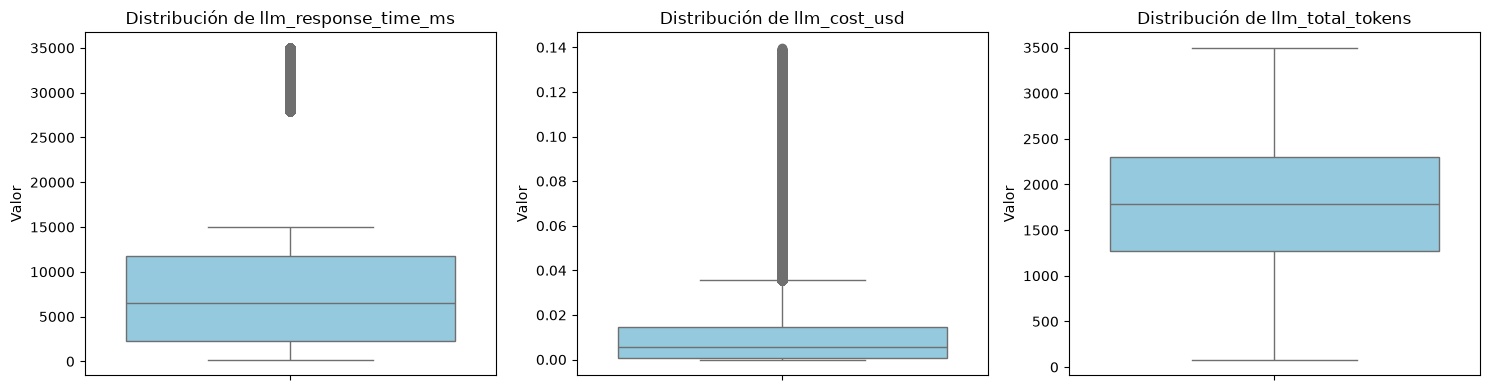

In [26]:
# Seleccionamos algunas variables numéricas continuas clave para el análisis
columnas_numericas = ['llm_response_time_ms', 'llm_cost_usd', 'llm_total_tokens']

print("=== ANÁLISIS DE OUTLIERS USANDO EL MÉTODO IQR ===\n")

for col in columnas_numericas:
    if col in df_llm.columns:
        # Eliminar nulos temporalmente solo para el cálculo matemático
        datos_col = df_llm[col].dropna()

        if len(datos_col) > 0:
            # Calcular cuartiles y rango intercuartílico
            q1 = datos_col.quantile(0.25)
            q3 = datos_col.quantile(0.75)
            iqr = q3 - q1

            # Límites para considerar un valor como atípico
            limite_inferior = q1 - 1.5 * iqr
            limite_superior = q3 + 1.5 * iqr

            # Identificar atípicos
            outliers = datos_col[(datos_col < limite_inferior) | (datos_col > limite_superior)]
            porcentaje_outliers = (len(outliers) / len(datos_col)) * 100

            print(f"Columna: '{col}'")
            print(f"   - Rango normal esperado: [{limite_inferior:.4f} a {limite_superior:.4f}]")
            print(f"   - Cantidad de outliers detectados: {len(outliers)} de {len(datos_col)} registros")
            print(f"   - Porcentaje de outliers: {porcentaje_outliers:.2f}%")
            print(f"   - Valor máximo registrado: {datos_col.max():.4f}\n")

# Generar boxplots para visualizar la distribución espacial de los outliers
plt.figure(figsize=(15, 4))
for i, col in enumerate(columnas_numericas, 1):
    if col in df_llm.columns:
        plt.subplot(1, 3, i)
        sns.boxplot(y=df_llm[col], color='skyblue')
        plt.title(f'Distribución de {col}')
        plt.ylabel('Valor')

plt.tight_layout()
plt.show()


Text(0, 0.5, 'Frecuencia')

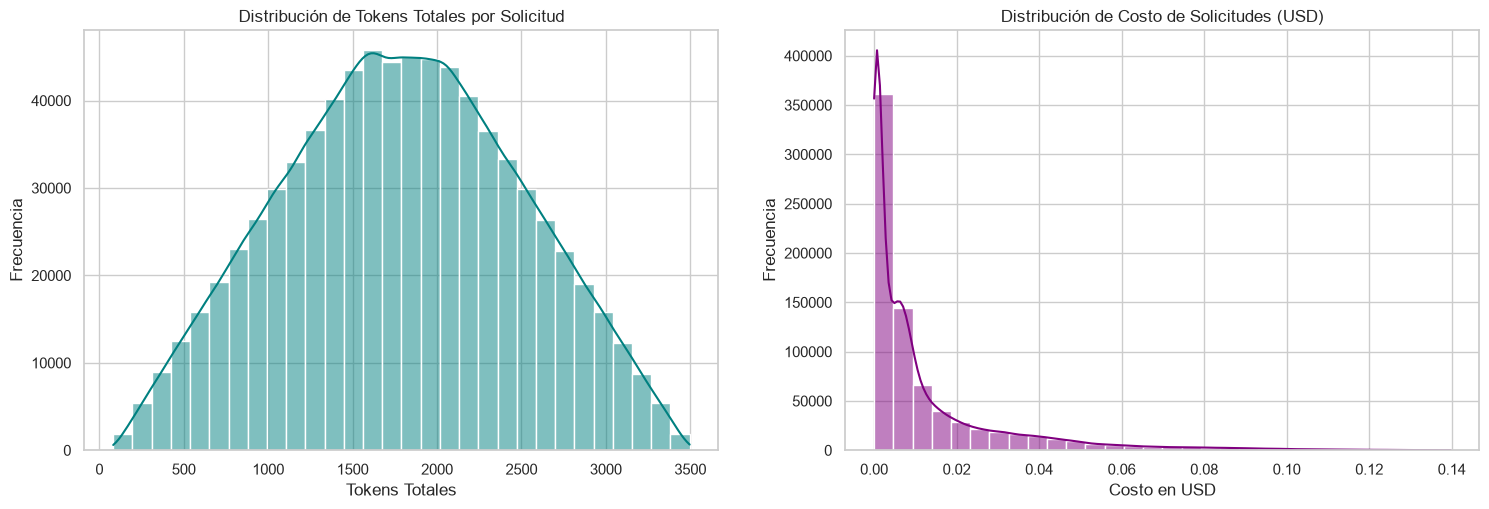

In [27]:
# ==========================================
# ANÁLISIS UNIVARIADO
# ==========================================

# Configurar estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(18, 12))

# 1. Variables Numéricas: Distribución de Costo e Histograma de Tokens
plt.subplot(2, 2, 1)
sns.histplot(data=df_llm, x='llm_total_tokens', bins=30, kde=True, color='teal')
plt.title('Distribución de Tokens Totales por Solicitud')
plt.xlabel('Tokens Totales')
plt.ylabel('Frecuencia')

plt.subplot(2, 2, 2)
sns.histplot(data=df_llm, x='llm_cost_usd', bins=30, kde=True, color='purple')
plt.title('Distribución de Costo de Solicitudes (USD)')
plt.xlabel('Costo en USD')
plt.ylabel('Frecuencia')

### Variables categóricas

In [24]:
revisar_categoricas(df_llm, clasificacion_variables_llm)

_index: 1 valores únicos
  Valores: ['llm-logs-2026.04']
headers_content_type: 5 valores únicos
  Valores: ['application/xml', 'multipart/form-data', 'application/x-www-form-urlencoded', 'application/json', 'text/plain']
headers_http_request_method: 5 valores únicos
  Valores: ['POST', 'DELETE', 'PATCH', 'GET', 'PUT']
heathers_request_path: 10 valores únicos
  Valores: ['/api/llm/sap-successfactors/completion', '/api/llm/sap-analytics-cloud/completion', '/api/llm/sap-fiori-launchpad/completion', '/api/llm/sap-concur/completion', '/api/llm/sap-intelligent-rpa/completion', '/api/llm/sap-ariba/completion', '/api/llm/sap-s4hana-finance/completion', '/api/llm/sap-data-sphere/completion', '/api/llm/sap-s4hana-sales/completion', '/api/llm/sap-btp-cf/completion']
sap_function_application: 10 valores únicos
  Valores: ['sap-successfactors', 'sap-analytics-cloud', 'sap-fiori-launchpad', 'sap-concur', 'sap-intelligent-rpa', 'sap-ariba', 'sap-s4hana-finance', 'sap-data-sphere', 'sap-s4hana-sales',

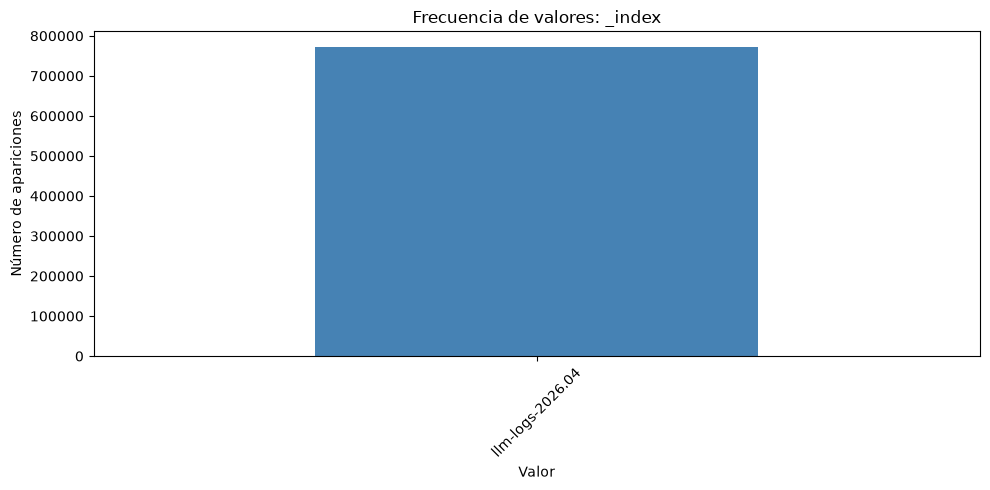

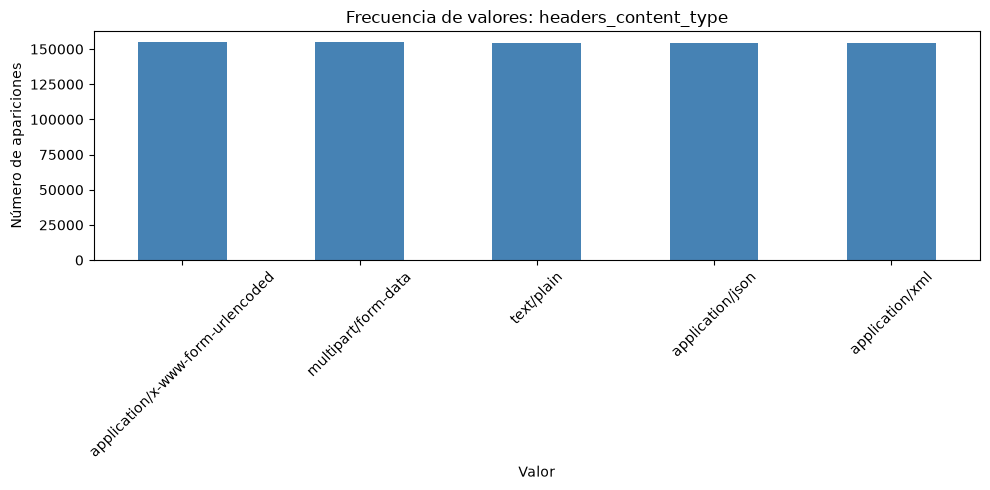

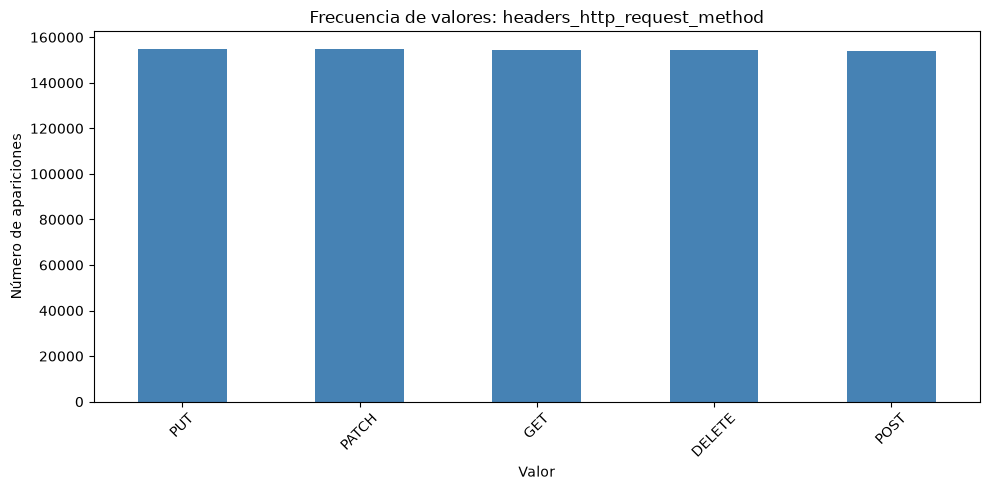

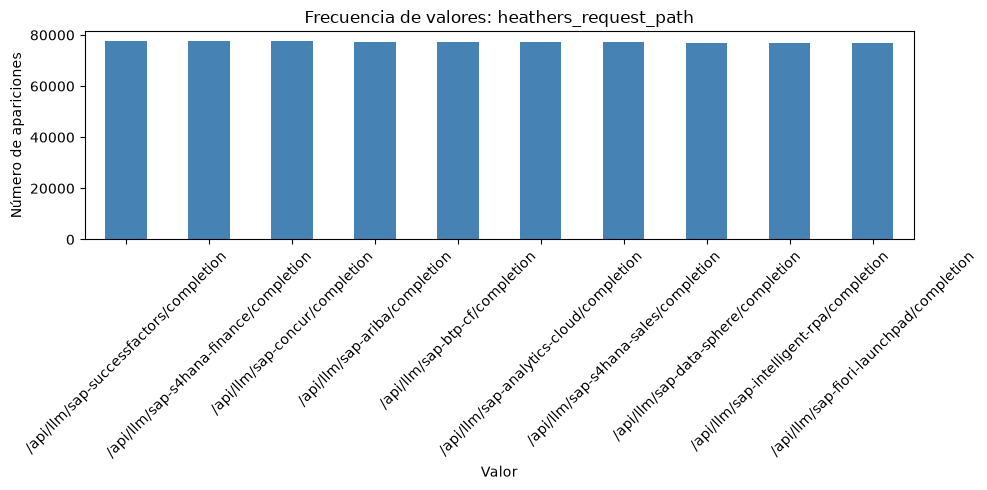

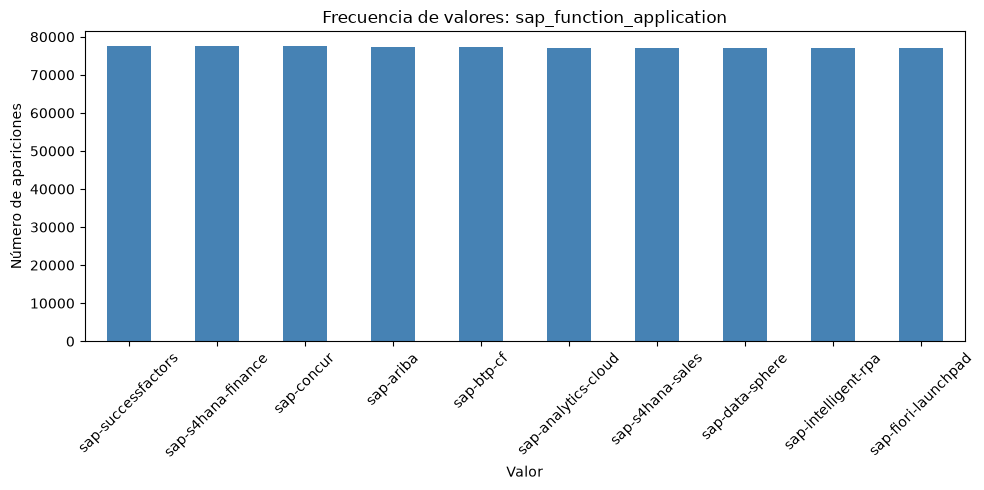

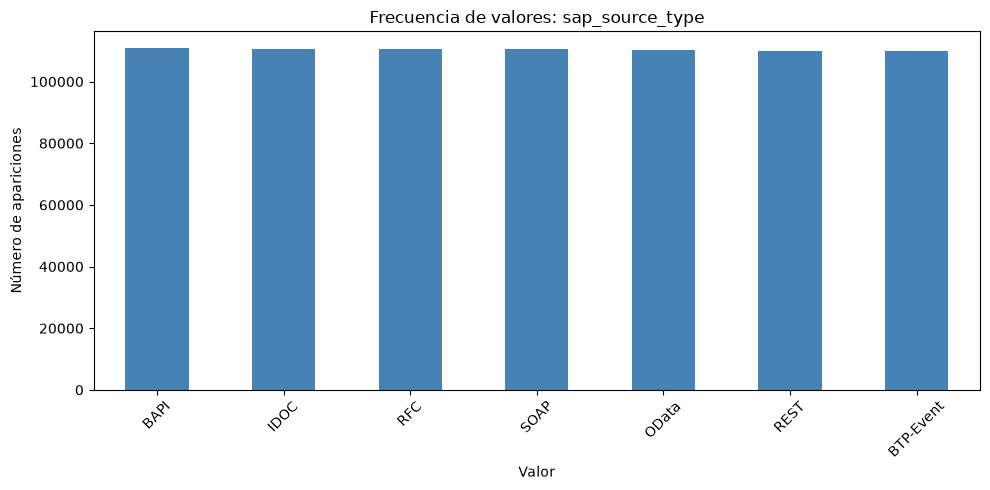

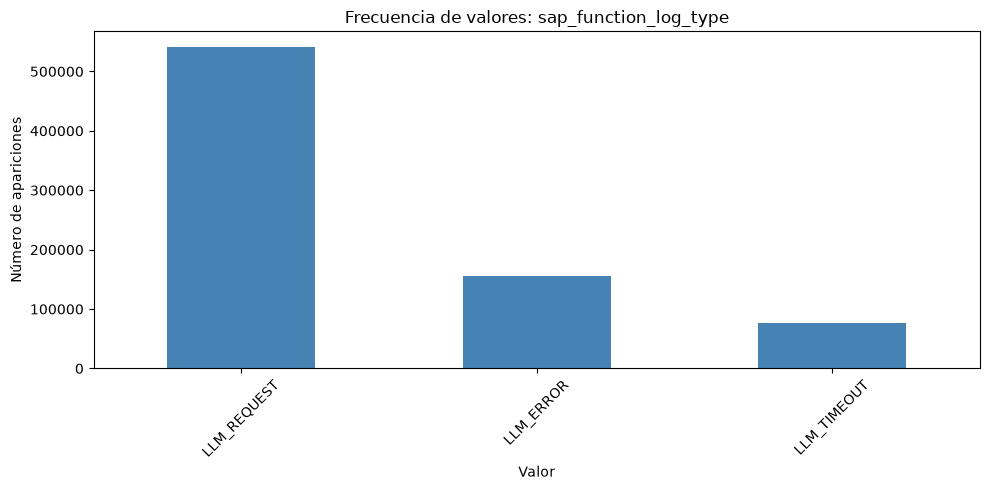

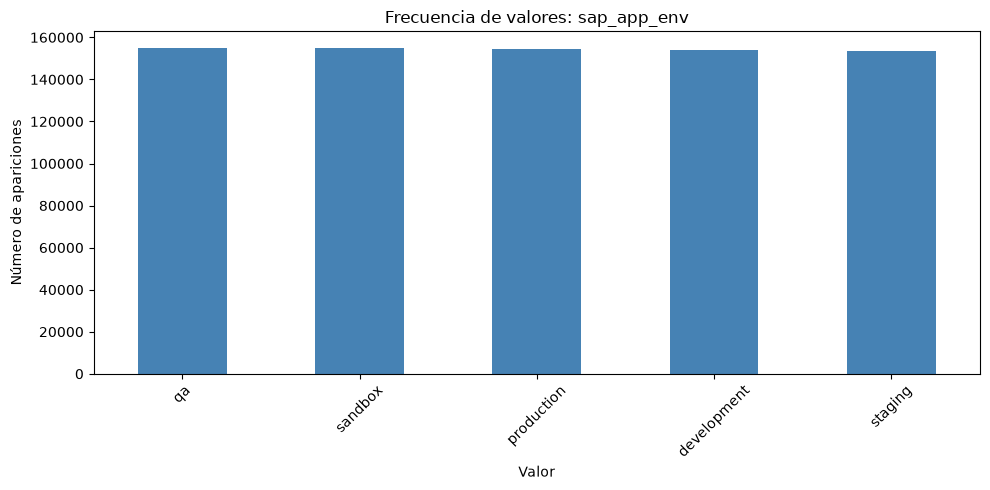

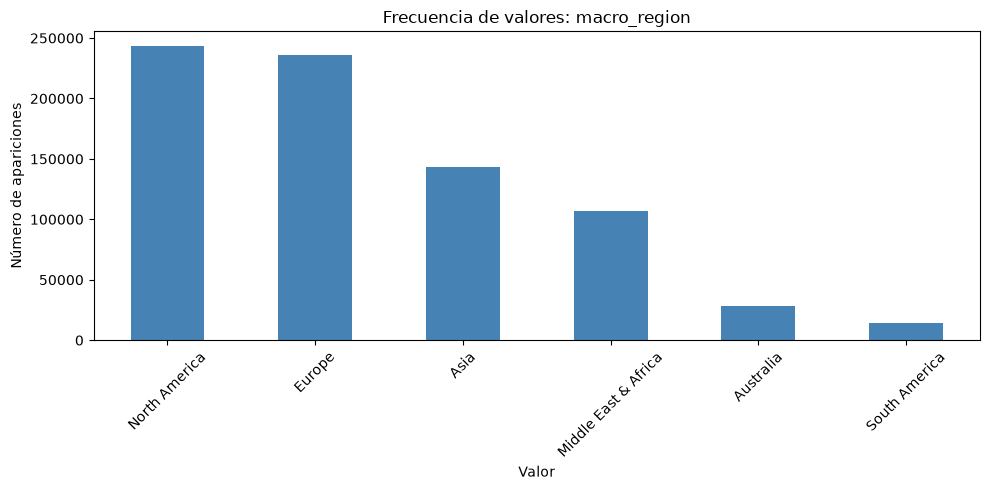

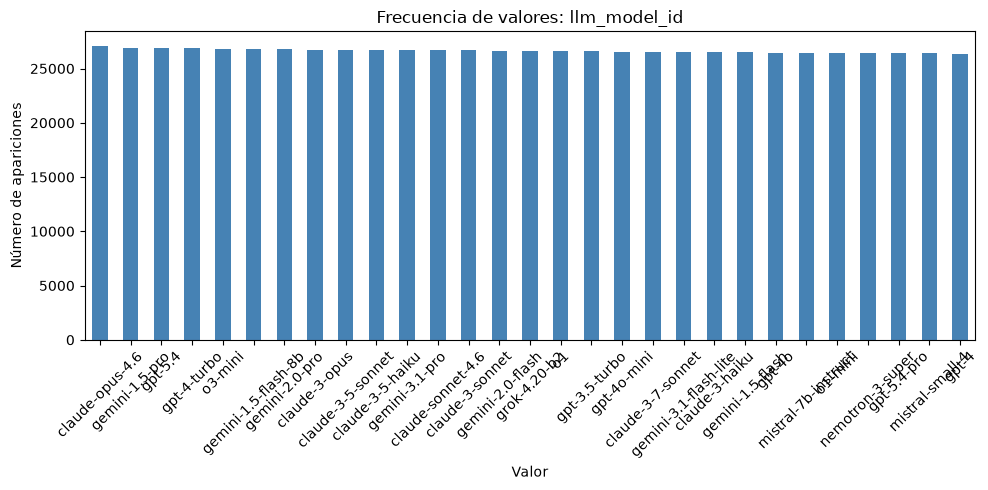

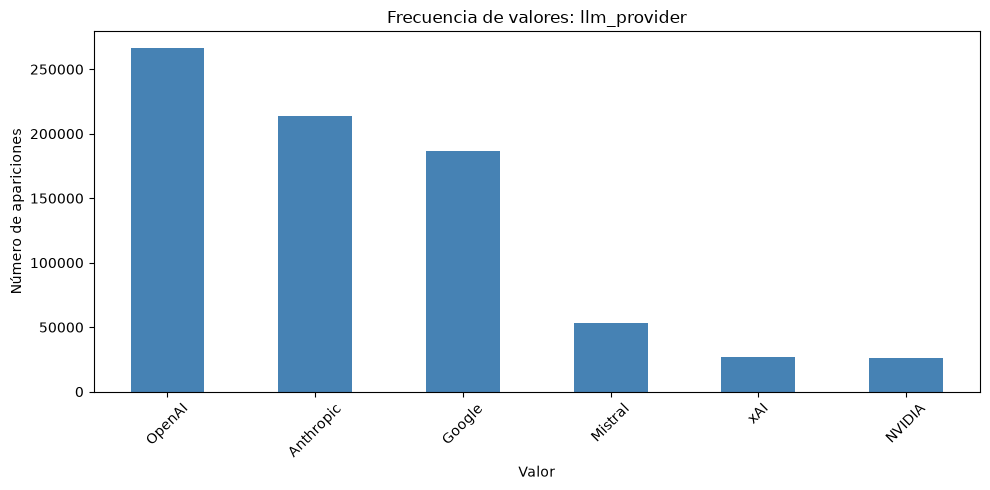

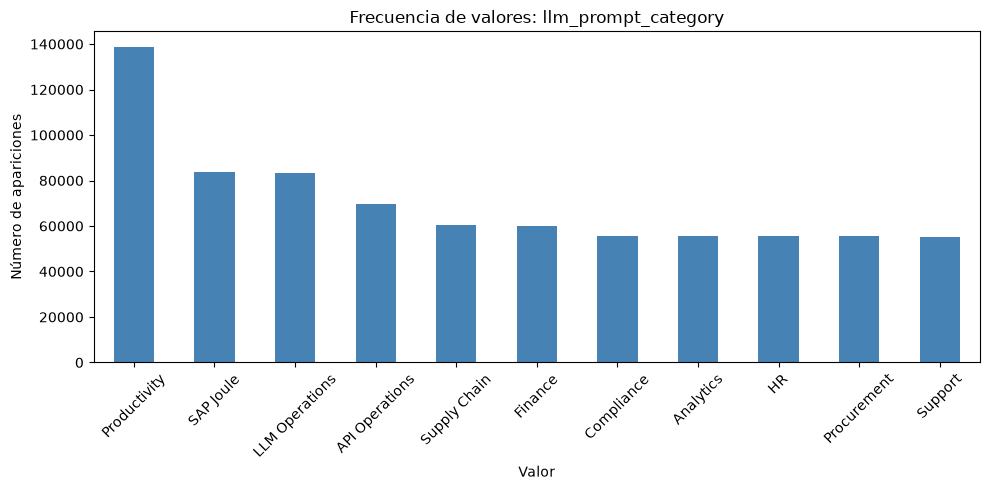

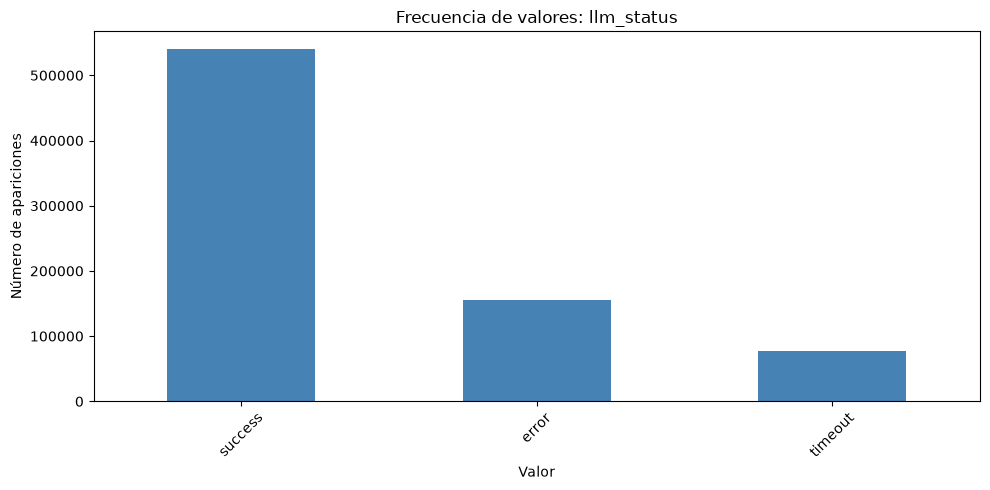

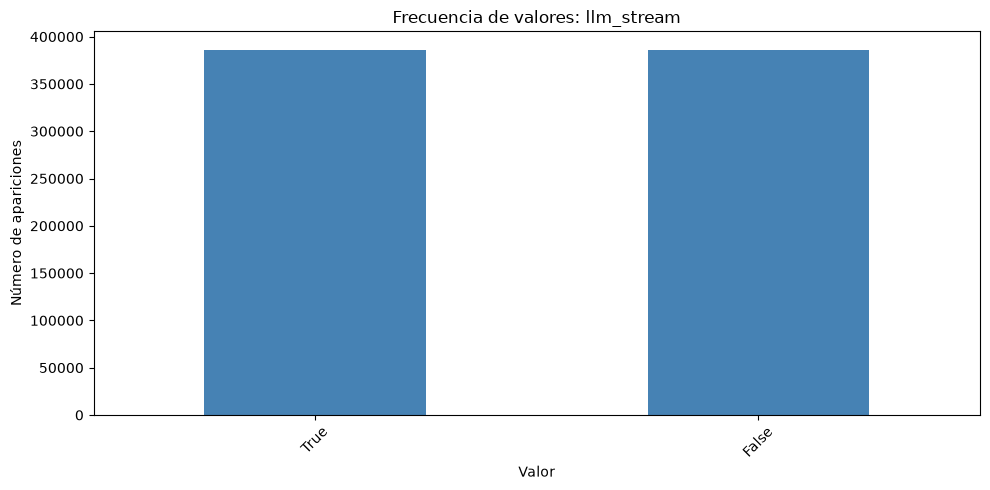

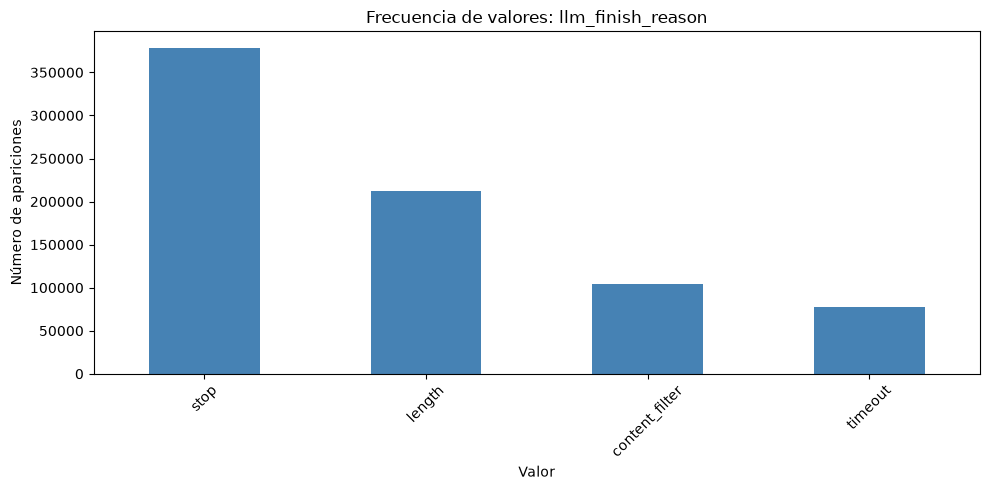

In [25]:
graficar_categoricas(df_llm, clasificacion_variables_llm)

### Conclusión Análisis LLM

Al igual que con el dataset de System, la mayoría de datos analizados en eventos aislados no son muy relevantes para el estudio, además es difícil la identificación de outliers sin tomar en cuenta ventanas de tiempo. Las variables clave identificadas en este dataset son "llm_response_time", "llm_finish_reason", "llm_status", "llm_prompt_category", "sap_app_env" y "headers_http_request_method".

Se eliminará la columna "_ignored" ya que cuenta con 100% de valores nulos y no aporta al análisis. También identificamos columnas que poseen valores nulos que pueden ser imputados con un "0" o un "no aplica" cuando sea el caso ya que columnas como "llm_error_message" o "sap_llm_response_time" solo tienen valores si se ejecuta o no el llm.

Se espera además de generar las ventanas con conteos agrupados de eventos, encontrar una forma de preservar el orden de operaciones de un mismo usuario dentro de esa ventana mediante cadenas de Markov o reglas del negocio que nos pudieran indicar de mejor forma si se intentó algún ciberataque.